In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cvxpy as cp
from functions import AlgPenDisc
from functions import AlgMePa
from functions import AlgRemez
from functions import AlgBF
from functions import AlgCoM
from functions import linear

In [2]:
#X,Y must be a box
Y=[(0,4*np.pi)]
n=3
A=np.zeros([6,3])
b=[1,1,100,1,1,0]
for i in range(n):
    A[i,i]=1
    A[n+1,i]=-1
X=[(linear,[A,b])]
norm=2
#DCP of f following cxvpy rules
def fcp(x):
    return x[2]
    
#DCP of g following cxvpy rules
def gcp(x,y):
    return cp.pnorm(x[0:2]-p(y),norm)-x[2]
    
def g(x,y):
    return np.linalg.norm(x[0:2]-p(y),norm)-x[2]   
    
#Curves
def p(y):
    return np.cos(y)[0],2*np.sin(y)[0]



def p(y):
    c=4.5
    d=4.5
    return c*np.cos(y)[0]-np.cos(c*y)[0],d*np.sin(y)[0]-np.sin(d*y)[0]

#def p(y):
    #c=40
    #return c*np.cos(y)[0]-np.cos(c*y)[0],np.sin(20*y)[0]+c*np.sin(y)[0]-np.sin(c*y)[0]


def circle(c,r,N):
    x=np.ones(N)
    y=np.ones(N)
    t = np.linspace(0, 2*np.pi, N)
    for i in range(N):
        x[i]=c[0]+r*np.cos(t[i])
        y[i]=c[0]+r*np.sin(t[i])
    return x,y

def square(c,r,N):
    x=np.ones(N)
    y=np.ones(N)
    t = np.linspace(0, 2*np.pi, N)
    for i in range(N):
        x[i]=c[0]+r*np.cos(t[i])
        y[i]=c[0]+r*np.sin(t[i])
    return x,y


In [3]:
x0=np.array([0,0,0])
y0=np.array([[0]])

In [4]:
res=AlgPenDisc(x0,y0,fcp,gcp,g,X,Y)

Time 0.1463475227355957
Time upper problem 0.09656810760498047
Time lower problem 0.049779415130615234
Feasibility 0.00019161466468897714
Final rho 1.5
Rho increases 1
Optimal value 5.499955453828471
Value function call 5


In [5]:
res=AlgRemez(x0,y0,fcp,gcp,g,X,Y)

Time 1.8939664363861084
Time upper problem 1.7660574913024902
Time lower problem 0.12790894508361816
Feasibility 3.900050022487278e-06
Optimal value 5.499998270900282
Value function call 23


In [6]:
res=AlgMePa(x0,y0,fcp,gcp,g,X,Y,Ub=1000)

Time 0.1795499324798584
Time upper problem 0.14196348190307617
Time lower problem 0.03758645057678223
Feasibility -0.0007973646040921878
Optimal value 5.499956697919392
Optimality cuts 2
Feasibility cuts 4
Value function calls 6


In [7]:
res=AlgBF(x0,y0,fcp,gcp,g,X,Y)

Time 0.13836002349853516
Time upper problem 0.06360101699829102
Time lower problem 0.07475900650024414
Feasibility 0.00019159137054547415
Optimal value 5.499955456872252
Value function call 4


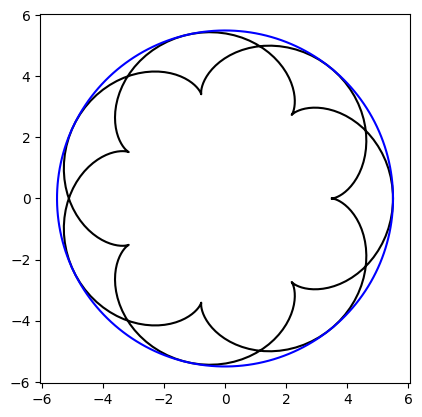

In [8]:
N = 400
t = np.linspace(Y[0][0], Y[0][1], N)
x=np.ones(N)
y=np.ones(N)
for i in range(N):
    x[i], y[i]= p(np.array([t[i]]))

fig, ax = plt.subplots()
ax.plot(x, y, "k")
ax.set(aspect=1)

center=res[0][0:2]
radius=res[0][2]

x1,y1=circle(center,radius,N)
ax.plot(x1, y1, "b")

In [4]:
cp.sum([1,2])

3